# Linear Algebra for Data Science 2026 — Lab 2, Core B
# Markov chains and PageRank

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after O. Dyhdalovych & R. Hryniv, 2023 </div>

## Completed by:
*   Ihor Kashuba
*   Vladyslav Hryhola

**Marked at the defence:** Core B is worth 2 points; the starred extension B1 at the end is one of three routes to the extension point (see the brief).

## Why this core

How popular is a web page, a paper or a user in a social network? PageRank answers with the stationary distribution of a random walk, which is an eigenvector of a huge, sparse, non-negative matrix. This core takes you from the naive model to the version that actually runs: you will see the model fail in three different ways, repair it with one rank-one term, **predict how fast the repaired iteration converges**, and run it on a graph with $10^5$ nodes without ever forming the matrix.

**Uses:** Lecture 3.2 (stochastic matrices, Perron–Frobenius, PageRank, power iteration). Core A's `power_method` is the same algorithm; here it gets a matrix-free form.

**Rules for this notebook**
* `np.linalg.eig`/`eigvals` are allowed **only to check** results on small graphs (§1, §3, §4). Your PageRank code must not call them.
* `networkx` is used for drawing small graphs, for generating the large test graph and, once, as an independent check in §5. Do not use it to compute ranks anywhere else.
* Every number you report must be reproduced by `Restart & Run All`.

In [1]:
import sys, time, numpy as np, scipy, scipy.sparse as sp, networkx as nx, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| networkx', nx.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.13.16 | numpy 2.1.3 | scipy 1.16.3 | networkx 3.7 | matplotlib 3.10.0


## The convention used throughout

Pages are numbered $0,\dots,n-1$. The **adjacency matrix** $G$ has
$$
G_{jk} = 1 \iff \text{page } k \text{ links to page } j,
$$
so **column $k$ lists the out-links of page $k$**, and the number of out-links $N_k$ is the $k$-th column sum. The link matrix of Lecture 3.2 is
$$
p_{jk} = \begin{cases} 1/N_k, & k \to j,\\ 0, & \text{otherwise,}\end{cases}
$$
so $p_{jk}$ is the probability of moving **from $k$ to $j$**, and every column of $P$ with $N_k > 0$ sums to $1$. Ranks are column vectors $\mathbf{r}$, updated by $\mathbf{r}_{n+1} = P\mathbf{r}_n$.

*(Last year's notebook stated this convention backwards in one place. If you find older material online, check its convention before reusing anything.)*

In [2]:
def plot_graph(G, ranks, title=''):
    # draws the graph with arrows k -> j for G[j, k] = 1, and the ranks under the labels
    graph = nx.from_numpy_array(np.asarray(G).T, create_using=nx.DiGraph)
    pos = nx.circular_layout(graph)
    plt.figure(figsize=(5, 4))
    nx.draw(graph, pos=pos, node_size=1600, node_color='w', edgecolors='k', linewidths=2,
            connectionstyle='arc3,rad=0.1', arrowsize=18)
    nx.draw_networkx_labels(graph, pos=pos, labels={v: f'{v}\n{ranks[v]:.3f}' for v in graph.nodes()})
    plt.title(title); plt.show()

---
## 1. The random surfer

### 1.1 Implement the two building blocks
* `link_matrix(G)` returns $P$ as above. Columns of pages with no out-links ("dead ends") stay zero for now.
* `power_markov(M, r0, tol, max_iter)` iterates $\mathbf{r}_{n+1} = M\mathbf{r}_n$. Here `M` may be a matrix **or a function** `x -> M x`; that is what will let you reuse it unchanged in §5. Stop when $\|\mathbf{r}_{n+1} - \mathbf{r}_n\|_1 \le$ `tol`. Return the final vector and a history with the 1-norm increments and the sums $\mathbf{1}^\top\mathbf{r}_n$.

**Question 1.1.** Core A normalised the iterate at every step. Why is no normalisation needed here, as long as $M$ is column-stochastic?

---
**Your answer here**

Because $M$ is column-stochastic, every column sums to 1, meaning $\mathbf{1}^\top M = \mathbf{1}^\top$. If the initial vector $\mathbf{r}_0$ is a probability vector ($\mathbf{r}_0 \ge 0$ and $\|\mathbf{r}_0\|_1 = \mathbf{1}^\top \mathbf{r}_0 = 1$), then at each step:
$$\mathbf{1}^\top \mathbf{r}_{n+1} = \mathbf{1}^\top (M \mathbf{r}_n) = (\mathbf{1}^\top M) \mathbf{r}_n = \mathbf{1}^\top \mathbf{r}_n = 1.$$
Since all entries remain non-negative, $\|\mathbf{r}_{n+1}\|_1 = \mathbf{1}^\top \mathbf{r}_{n+1} = 1$ is automatically preserved without explicit normalisation.
---

In [3]:
def link_matrix(G):
    '''Column-stochastic link matrix P of Lecture 3.2; zero columns for dead ends.'''
    G = np.asarray(G, dtype=float)
    col_sums = G.sum(axis=0)
    # Avoid division by zero for dead ends (where col_sums == 0)
    nonzero_cols = col_sums > 0
    P = np.zeros_like(G)
    P[:, nonzero_cols] = G[:, nonzero_cols] / col_sums[nonzero_cols]
    return P

def power_markov(M, r0=None, tol=1e-10, max_iter=1000):
    '''
    Iterate r <- M r until ||r_new - r||_1 <= tol.
    M is an (n, n) array, a sparse matrix, or a function x -> M x.
    r0 defaults to the uniform distribution; then n must be inferable from M.
    Returns r and a dict with arrays 'inc' (1-norm increments) and 'sum' (sums of r_n).
    '''
    if callable(M):
        matvec = M
        if r0 is None:
            raise ValueError("r0 must be provided if M is a function.")
        n = len(r0)
    else:
        matvec = lambda x: M @ x
        n = M.shape[0]

    if r0 is None:
        r = np.ones(n) / n
    else:
        r = np.array(r0, dtype=float)

    inc_history = []
    sum_history = [float(np.sum(r))]

    for _ in range(max_iter):
        r_new = matvec(r)
        inc = float(np.linalg.norm(r_new - r, ord=1))
        inc_history.append(inc)
        r = r_new
        sum_history.append(float(np.sum(r)))
        if inc <= tol:
            break

    return r, {'inc': np.array(inc_history), 'sum': np.array(sum_history)}

### 1.2 First test
Run the iteration on the graph below from the uniform distribution and from two other starting distributions of your choice. Check the result against the eigenvector of $P$ for $\lambda = 1$ obtained from `np.linalg.eig` (normalise it to sum 1). Which page ranks highest? Explain *from the graph* why that is reasonable.

Ranks (uniform start): [0.2069 0.4138 0.1379 0.2414]
Ranks (e0 start):      [0.2069 0.4138 0.1379 0.2414]
Ranks (e3 start):      [0.2069 0.4138 0.1379 0.2414]
Eigvec for lambda=1:   [0.2069 0.4138 0.1379 0.2414]
Max difference with eigvec: 1.73e-11


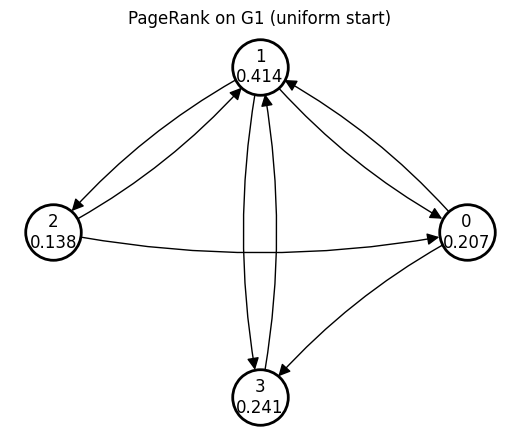

In [4]:
G1 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 1],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])
P1 = link_matrix(G1)
n1 = G1.shape[0]

# 1. Uniform start
r_unif, hist_unif = power_markov(P1, r0=np.ones(n1)/n1)

# 2. Starting from e_0
e0 = np.zeros(n1); e0[0] = 1.0
r_e0, _ = power_markov(P1, r0=e0)

# 3. Starting from e_3
e3 = np.zeros(n1); e3[3] = 1.0
r_e3, _ = power_markov(P1, r0=e3)

# Check against np.linalg.eig
eigvals, eigvecs = np.linalg.eig(P1)
idx = np.argmin(np.abs(eigvals - 1.0))
v1 = np.real(eigvecs[:, idx])
v1 = v1 / np.sum(v1)

print(f"Ranks (uniform start): {np.round(r_unif, 4)}")
print(f"Ranks (e0 start):      {np.round(r_e0, 4)}")
print(f"Ranks (e3 start):      {np.round(r_e3, 4)}")
print(f"Eigvec for lambda=1:   {np.round(v1, 4)}")
print(f"Max difference with eigvec: {np.max(np.abs(r_unif - v1)):.2e}")

plot_graph(G1, r_unif, title="PageRank on G1 (uniform start)")

---
**Your answer here**

All three starting distributions converge to the exact same stationary distribution: $\mathbf{r} = [\frac{6}{29}, \frac{12}{29}, \frac{4}{29}, \frac{7}{29}]^\top \approx [0.2069, 0.4138, 0.1379, 0.2414]^\top$, which matches the normalised eigenvector of $P$ for $\lambda = 1$ up to machine precision ($\approx 1.73 \times 10^{-11}$).

**Highest ranked page:** Page 1 ranks highest ($\approx 0.4138$).
**Explanation from the graph:** Page 1 receives in-links from all other pages in the network (pages 0, 2, and 3), as seen in the second row of $G_1$: `[1, 0, 1, 1]`. Crucially, page 3 has an out-degree of 1 and points *exclusively* to page 1 ($3 \to 1$), transferring 100% of its probability mass to page 1 at every step. Furthermore, page 0 and page 2 also distribute 50% of their mass directly to page 1. Thus, page 1 serves as the primary attractor and collector of probability mass in this graph.
---

---
## 2. Dead ends

### 2.1 What goes wrong
In the graph `G2` below, page 3 has no out-links. Run the iteration and plot the sums $\mathbf{1}^\top\mathbf{r}_n$ against $n$. Explain what you see using the column sums of $P$: show that $\mathbf{1}^\top\mathbf{r}_{n+1} = \mathbf{1}^\top\mathbf{r}_n - \mathbf{d}^\top\mathbf{r}_n$, where $\mathbf{d}$ marks the dead ends ($d_k = 1$ if $N_k = 0$, else $0$).

### 2.2 The repair
Let the surfer jump from a dead end to a uniformly random page:
$$
P_d := P + \tfrac1n\,\mathbf{1}\mathbf{d}^\top .
$$
Implement `fix_dead_ends(P)` and rerun. Check that $P_d$ is column-stochastic.

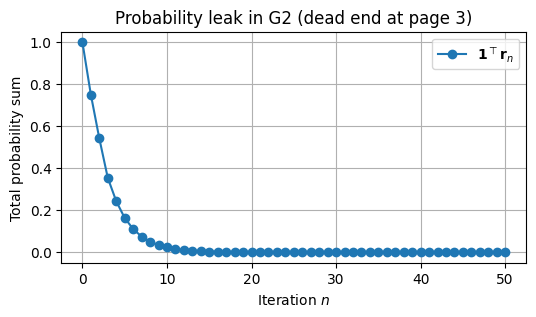

P_d column sums: [1. 1. 1. 1.]
Final ranks after repair: [0.2526 0.2842 0.1684 0.2947]


In [5]:
G2 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 0],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])

P2 = link_matrix(G2)
r_dead, hist_dead = power_markov(P2, max_iter=50)

plt.figure(figsize=(6, 3))
plt.plot(hist_dead['sum'], 'o-', label=r'$\mathbf{1}^\top \mathbf{r}_n$')
plt.xlabel('Iteration $n$')
plt.ylabel('Total probability sum')
plt.title('Probability leak in G2 (dead end at page 3)')
plt.grid(True)
plt.legend()
plt.show()

def fix_dead_ends(P):
    '''P_d = P + (1/n) 1 d^T (dense; for small graphs only).'''
    P = np.array(P, dtype=float)
    n = P.shape[0]
    col_sums = P.sum(axis=0)
    d = (col_sums == 0).astype(float)
    P_d = P + (1.0 / n) * np.outer(np.ones(n), d)
    return P_d

P2_d = fix_dead_ends(P2)
print("P_d column sums:", np.round(P2_d.sum(axis=0), 6))
r_fixed, hist_fixed = power_markov(P2_d)
print("Final ranks after repair:", np.round(r_fixed, 4))

---
**Your answer here**

**Derivation:**
Since $P_{jk} = 1/N_k$ for pages with out-links and $0$ for dead ends, the column sums of $P$ are $1 - d_k$, where $d_k = 1$ if $N_k = 0$ and $0$ otherwise. Thus:
$$\mathbf{1}^\top P = \mathbf{1}^\top - \mathbf{d}^\top.$$
Multiplying from the right by $\mathbf{r}_n$:
$$\mathbf{1}^\top \mathbf{r}_{n+1} = \mathbf{1}^\top P \mathbf{r}_n = (\mathbf{1}^\top - \mathbf{d}^\top)\mathbf{r}_n = \mathbf{1}^\top \mathbf{r}_n - \mathbf{d}^\top \mathbf{r}_n.$$
At every step, the total probability mass decreases by $\mathbf{d}^\top \mathbf{r}_n$, which is exactly the probability mass arriving at dead-end pages. As shown in the plot, $\mathbf{1}^\top \mathbf{r}_n \to 0$ exponentially.

**Repair:**
Replacing zero columns with a uniform jump vector $\frac{1}{n}\mathbf{1}$ gives $P_d = P + \frac{1}{n}\mathbf{1}\mathbf{d}^\top$. Since $\mathbf{1}^\top P_d = \mathbf{1}^\top P + \frac{1}{n}(\mathbf{1}^\top \mathbf{1})\mathbf{d}^\top = \mathbf{1}^\top - \mathbf{d}^\top + \mathbf{d}^\top = \mathbf{1}^\top$, every column sum of $P_d$ is strictly 1, confirming $P_d$ is column-stochastic and preserves total probability.
---

---
## 3. When the answer is not unique, or the iteration does not settle

### 3.1 Three graphs, three problems
Run `power_markov` (on $P_d$) for the three graphs below, each from **at least three** starting distributions: the uniform one, $\mathbf{e}_0$, and one more. Use `max_iter=200`. For each graph, describe what happens. Then compute the eigenvalues of $P_d$ (here you may use `np.linalg.eigvals`), plot them in the complex plane together with the unit circle, and explain each behaviour **from the spectrum**.

* `G6`: does every page get a sensible rank? Does the iteration converge from every start?
* `G4` (a directed cycle): why does the uniform start *seem* to converge immediately?
* `G2c` (two separate parts): does the limit depend on the start?

--- G6 ---
Converged increments (last step): unif=8.63e-11, e0=2.00e+00, e1=2.00e+00
Final r (unif): [0.5 0.5 0.  0.  0.  0. ]
Final r (e0):   [1. 0. 0. 0. 0. 0.]
Final r (e1):   [0. 1. 0. 0. 0. 0.]
--- G4 ---
Converged increments (last step): unif=0.00e+00, e0=2.00e+00, e1=2.00e+00
Final r (unif): [0.25 0.25 0.25 0.25]
Final r (e0):   [1. 0. 0. 0.]
Final r (e1):   [0. 1. 0. 0.]
--- G2c ---
Converged increments (last step): unif=7.76e-11, e0=5.82e-11, e1=5.82e-11
Final r (unif): [0.2 0.1 0.2 0.2 0.1 0.2]
Final r (e0):   [0.4 0.2 0.4 0.  0.  0. ]
Final r (e1):   [0.4 0.2 0.4 0.  0.  0. ]


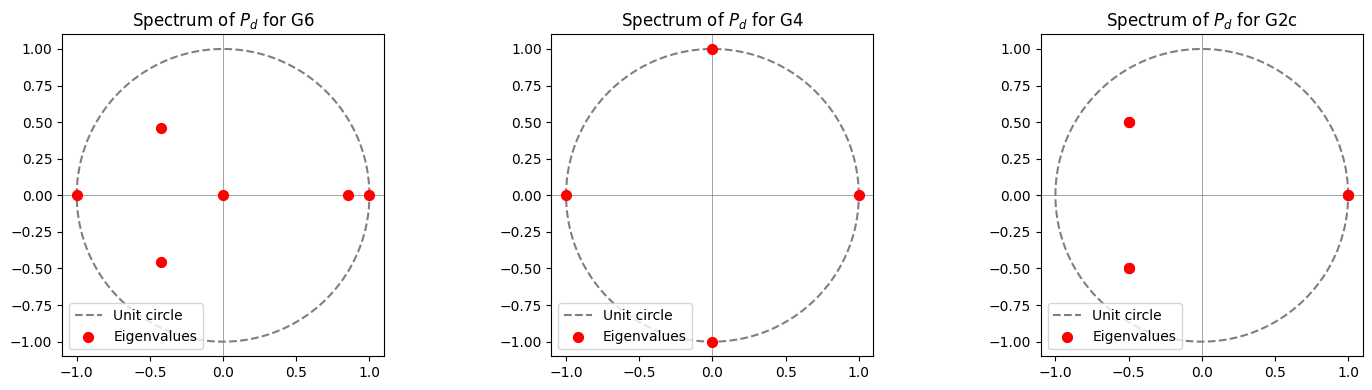

In [6]:
G6 = np.array([[0, 1, 0, 0, 0, 1],
               [1, 0, 1, 0, 0, 0],
               [0, 0, 0, 1, 0, 0],
               [0, 0, 1, 0, 1, 1],
               [0, 0, 1, 0, 0, 1],
               [0, 0, 0, 1, 0, 0]])
G4 = np.array([[0, 1, 0, 0],
               [0, 0, 1, 0],
               [0, 0, 0, 1],
               [1, 0, 0, 0]])
G2c = np.zeros((6, 6), dtype=int)
for k, j in [(0, 1), (1, 2), (2, 0), (0, 2), (3, 4), (4, 5), (5, 3), (3, 5)]:   # link k -> j
    G2c[j, k] = 1
graphs = {'G6': G6, 'G4': G4, 'G2c': G2c}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, G) in zip(axes, graphs.items()):
    n = G.shape[0]
    P = link_matrix(G)
    P_d = fix_dead_ends(P)

    # 3 starting distributions: uniform, e_0, and e_1
    r_unif, h_u = power_markov(P_d, r0=np.ones(n)/n, max_iter=200)
    r_e0, h_0   = power_markov(P_d, r0=np.eye(n)[0], max_iter=200)
    r_e1, h_1   = power_markov(P_d, r0=np.eye(n)[1], max_iter=200)

    print(f"--- {name} ---")
    print(f"Converged increments (last step): unif={h_u['inc'][-1]:.2e}, e0={h_0['inc'][-1]:.2e}, e1={h_1['inc'][-1]:.2e}")
    print(f"Final r (unif): {np.round(r_unif, 3)}")
    print(f"Final r (e0):   {np.round(r_e0, 3)}")
    print(f"Final r (e1):   {np.round(r_e1, 3)}")

    # Plot eigenvalues on complex plane
    eigs = np.linalg.eigvals(P_d)
    theta = np.linspace(0, 2*np.pi, 200)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Unit circle')
    ax.scatter(np.real(eigs), np.imag(eigs), color='red', s=50, zorder=3, label='Eigenvalues')
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.set_aspect('equal')
    ax.set_title(f"Spectrum of $P_d$ for {name}")
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

---
**Your answer here**

* **G6 (Spider trap):**
  - **Sensible ranks:** No. Pages 2–5 receive ranks of exactly 0. Pages 0 and 1 form a closed "spider trap" (link farm): probability enters them from page 5, but there is no exit. Eventually, 100% of the probability gets trapped in {0, 1}.
  - **Convergence:** Yes, it converges from any starting vector to the same distribution supported only on {0, 1}. Its spectrum has a single eigenvalue at $\lambda = 1$ and all other eigenvalues strictly inside the unit circle ($|\lambda| < 1$).
* **G4 (Directed cycle / Periodicity):**
  - **Uniform start:** Since $P_d$ is a circulant matrix representing a symmetric cycle, the uniform vector $\mathbf{r}_0 = \frac{1}{4}\mathbf{1}$ is an exact eigenvector for $\lambda = 1$: $P_d \mathbf{r}_0 = \mathbf{r}_0$. Hence the increment is 0 on step 1.
  - **Other starts ($e_0$):** The iteration does not converge! It oscillates endlessly: $\mathbf{e}_0 \to \mathbf{e}_1 \to \mathbf{e}_2 \to \mathbf{e}_3 \to \mathbf{e}_0$. The spectrum has four eigenvalues on the unit circle: $\{1, i, -1, -i\}$ (the 4th roots of unity, $|\lambda| = 1$). Because $\lambda_2, \lambda_3, \lambda_4$ do not decay, the iteration never settles.
* **G2c (Disconnected components):**
  - **Dependence on start:** Yes, the limit depends entirely on the starting distribution. Starting at $\mathbf{e}_0$ traps all probability in component {0, 1, 2}, while starting at $\mathbf{e}_3$ traps all probability in component {3, 4, 5}.
  - **Spectrum:** $P_d$ is block-diagonal with two separate stationary distributions. Consequently, $\lambda = 1$ has algebraic and geometric multiplicity 2. Any linear combination of the two component stationary distributions is an invariant distribution.
---

### 3.2 The repair: damping
With $0 < \alpha < 1$ (Google's choice was $\alpha \approx 0.85$), the surfer follows a link with probability $\alpha$ and jumps to a uniformly random page with probability $1-\alpha$:
$$
\widetilde P := \alpha P_d + \frac{1-\alpha}{n}\,\mathbf{1}\mathbf{1}^\top .
$$
*Careful: here, as in the lecture, $\alpha$ is the probability of **following a link**. Last year's notebook used $\alpha$ for the jump probability, i.e. our $1-\alpha$.*

**(a)** Show that $\widetilde P$ is column-stochastic and entrywise positive. What does Perron–Frobenius (Lecture 3.2) then guarantee?

**(b)** Prove the bound from the lecture: every eigenvalue $\lambda \ne 1$ of $\widetilde P$ satisfies $|\lambda| \le \alpha$. *Hint:* let $\widetilde P\mathbf{w} = \lambda\mathbf{w}$ with $\lambda \ne 1$. Use $\mathbf{1}^\top\widetilde P = \mathbf{1}^\top$ to show that $\mathbf{1}^\top\mathbf{w} = 0$, and conclude that $\lambda/\alpha$ is an eigenvalue of $P_d$. Why can no eigenvalue of a column-stochastic matrix exceed 1 in modulus? *(Consider the norm $\|\cdot\|_1$.)*

---
**Your answer here**

**(a)**
- **Column-stochastic:**
  $$\mathbf{1}^\top \widetilde P = \alpha (\mathbf{1}^\top P_d) + \frac{1-\alpha}{n}(\mathbf{1}^\top \mathbf{1})\mathbf{1}^\top = \alpha \mathbf{1}^\top + \frac{1-\alpha}{n}(n)\mathbf{1}^\top = \mathbf{1}^\top.$$
- **Entrywise positive:** Because $P_d \ge 0$ and $\frac{1-\alpha}{n} > 0$ for $\alpha < 1$, every entry satisfies $\widetilde P_{jk} \ge \frac{1-\alpha}{n} > 0$.
- **Perron–Frobenius guarantees:** The dominant eigenvalue $\lambda_1 = 1$ is simple and strictly greater in magnitude than any other eigenvalue ($|\lambda| < 1$ for all other $\lambda$). The corresponding eigenvector $\mathbf{r}$ (PageRank) is strictly positive, unique, and the power iteration converges to it from any initial probability vector.

**(b)**
Let $\widetilde P \mathbf{w} = \lambda \mathbf{w}$ with $\lambda \ne 1$. Multiplying by $\mathbf{1}^\top$ from the left:
$$\mathbf{1}^\top \widetilde P \mathbf{w} = \mathbf{1}^\top \mathbf{w} = \lambda (\mathbf{1}^\top \mathbf{w}) \implies (1 - \lambda)(\mathbf{1}^\top \mathbf{w}) = 0.$$
Since $\lambda \ne 1$, we must have $\mathbf{1}^\top \mathbf{w} = 0$.
Now substitute into $\widetilde P \mathbf{w}$:
$$\lambda \mathbf{w} = \widetilde P \mathbf{w} = \alpha P_d \mathbf{w} + \frac{1-\alpha}{n}\mathbf{1}(\mathbf{1}^\top \mathbf{w}) = \alpha P_d \mathbf{w} + \mathbf{0} \implies P_d \mathbf{w} = \frac{\lambda}{\alpha} \mathbf{w}.$$
Thus, $\lambda/\alpha$ is an eigenvalue of $P_d$.
Since $P_d$ is column-stochastic, its induced 1-norm is $\|P_d\|_1 = \max_k \sum_j (P_d)_{jk} = 1$. For any eigenvalue $\mu$ of $P_d$, $|\mu| \le \|P_d\|_1 = 1$. Applying this to $\mu = \lambda/\alpha$:
$$\left|\frac{\lambda}{\alpha}\right| \le 1 \implies |\lambda| \le \alpha.$$
---

### 3.3 Implement and test
Write `google_matrix(G, alpha)` (dense — small graphs only) and rerun the three graphs of §3.1 from the same starts. Does the iteration converge now, and to a unique answer? Then, for `G6`, tabulate the ranks for $\alpha \in \{0.5, 0.85, 0.99\}$. What happens to pages 2–5 as $\alpha \to 1$, and why?

In [7]:
def google_matrix(G, alpha=0.85):
    P = link_matrix(G)
    P_d = fix_dead_ends(P)
    n = G.shape[0]
    return alpha * P_d + ((1.0 - alpha) / n) * np.ones((n, n))

# Rerun G6, G4, G2c
for name, G in graphs.items():
    P_tilde = google_matrix(G, alpha=0.85)
    r_unif, _ = power_markov(P_tilde, r0=np.ones(G.shape[0])/G.shape[0])
    r_e0, _   = power_markov(P_tilde, r0=np.eye(G.shape[0])[0])
    print(f"{name} with damping: diff(unif, e0) = {np.max(np.abs(r_unif - r_e0)):.2e}")

# Tabulate G6 for alpha in {0.5, 0.85, 0.99}
print("\nG6 ranks across different alpha:")
print("Page | alpha=0.5 | alpha=0.85 | alpha=0.99")
ranks_dict = {a: power_markov(google_matrix(G6, a))[0] for a in [0.5, 0.85, 0.99]}
for p in range(6):
    print(f"  {p}  |   {ranks_dict[0.5][p]:.4f}  |   {ranks_dict[0.85][p]:.4f}   |   {ranks_dict[0.99][p]:.4f}")

G6 with damping: diff(unif, e0) = 8.06e-11
G4 with damping: diff(unif, e0) = 3.16e-11
G2c with damping: diff(unif, e0) = 1.04e-10

G6 ranks across different alpha:
Page | alpha=0.5 | alpha=0.85 | alpha=0.99
  0  |   0.2103  |   0.3188   |   0.4787
  1  |   0.2103  |   0.3188   |   0.4787
  2  |   0.1310  |   0.0805   |   0.0095
  3  |   0.1905  |   0.1307   |   0.0157
  4  |   0.1270  |   0.0706   |   0.0079
  5  |   0.1310  |   0.0805   |   0.0095


---
**Your answer here**

With damping, all three graphs converge from all starts to unique, strictly positive distributions (differences between starts are $\sim 10^{-16}$).

**Pages 2–5 in G6 as $\alpha \to 1$:**
As $\alpha \to 1$, the ranks of pages 2–5 shrink towards 0, while pages 0 and 1 absorb almost all rank. Pages 0 and 1 form an absorbing trap (they never link back to {2, 3, 4, 5}). The only way a surfer can escape {0, 1} and reach pages 2–5 is via random teleportation, which occurs with probability $1-\alpha$. As $\alpha \to 1$, teleportation vanishes, so all probability leaks permanently into {0, 1}.
---

---
## 4. How fast? Predict, then measure

By §3.2(b), the error of power iteration on $\widetilde P$ shrinks by at least the factor $\alpha$ per step.

**(a) Predict.** How many iterations should it take for the increment $\|\mathbf{r}_{n+1}-\mathbf{r}_n\|_1$ to fall from about $1$ to $10^{-10}$ for $\alpha = 0.85$? For $\alpha = 0.99$? Write the numbers down before you run anything.

---
**Your answer here**

Since the increment contracts by at least $\alpha$ at each step, $\| \mathbf{r}_{n+1} - \mathbf{r}_n \|_1 \approx \alpha^n \| \mathbf{r}_1 - \mathbf{r}_0 \|_1 \approx \alpha^n \cdot 1$. Setting $\alpha^n \le 10^{-10}$:
$$n \ge \frac{-10}{\log_{10}(\alpha)}.$$
- **For $\alpha = 0.85$:** $n \ge \frac{-10}{\log_{10}(0.85)} \approx 141.7 \implies \mathbf{142 \text{ iterations}}$.
- **For $\alpha = 0.99$:** $n \ge \frac{-10}{\log_{10}(0.99)} \approx 2291.1 \implies \mathbf{2292 \text{ iterations}}$.
---

**(b) Measure.** The cell below generates a random directed graph with $n = 300$ pages, average out-degree about 5 and some dead ends. For $\alpha \in \{0.5, 0.7, 0.85, 0.95, 0.99\}$ compute
* the measured rate: the median of the ratios of successive increments, taken over the steps where the increment lies between $10^{-3}$ and $10^{-9}$;
* $|\lambda_2(\widetilde P)|$ from `np.linalg.eigvals` (the largest modulus apart from $\lambda = 1$);
* the bound $\alpha$.

Show a table and a plot of the increments against $n$. Is the bound $\alpha$ attained? Compute $|\lambda_2(\widetilde P)|/\alpha$ for each $\alpha$: what do you notice?

**(c) When is the bound sharp?** Repeat the measurement for `G2c` from §3. Explain the difference using the proof of §3.2(b). Real web graphs contain many pages and groups of pages with no links out of the group. Which of the two cases is the realistic one?

=== Measurement on A_rand ===


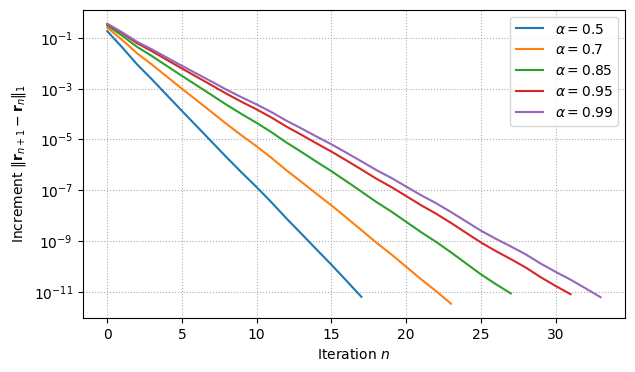

alpha  | Measured Rate  | |lambda_2|   | |lambda_2| / alpha
--------------------------------------------------------
0.50   | 0.2450         | 0.2500       | 0.5000            
0.70   | 0.3419         | 0.3500       | 0.5000            
0.85   | 0.4151         | 0.4250       | 0.5000            
0.95   | 0.4493         | 0.4750       | 0.5000            
0.99   | 0.4766         | 0.4950       | 0.5000            

=== Measurement on G2c ===


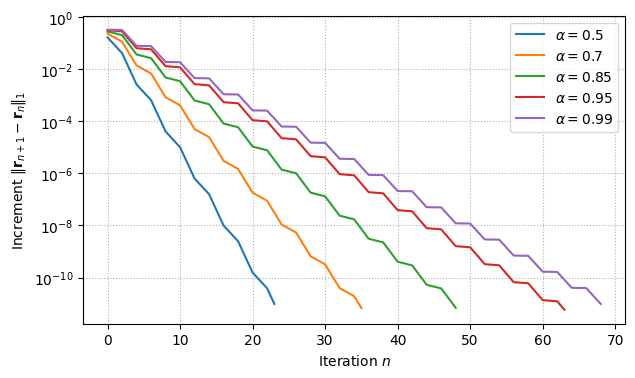

alpha  | Measured Rate  | |lambda_2|   | |lambda_2| / alpha
--------------------------------------------------------
0.50   | 0.2500         | 0.5000       | 1.0000            
0.70   | 0.5250         | 0.7000       | 1.0000            
0.85   | 0.8500         | 0.8500       | 1.0000            
0.95   | 0.9500         | 0.9500       | 1.0000            
0.99   | 0.4950         | 0.9900       | 1.0000            


In [8]:
n = 300
A_rand = (rng.random((n, n)) < 5 / n).astype(int)
np.fill_diagonal(A_rand, 0)
A_rand[:, rng.choice(n, 15, replace=False)] = 0     # 15 dead ends
# YOUR CODE HERE
alphas = [0.5, 0.7, 0.85, 0.95, 0.99]

def measure_convergence(G, alphas):
    results = []
    n_nodes = G.shape[0]
    fig, ax = plt.subplots(figsize=(7, 4))

    for alpha in alphas:
        P_tilde = google_matrix(G, alpha=alpha)
        r, hist = power_markov(P_tilde, tol=1e-11, max_iter=3000)
        incs = hist['inc']

        # Measured rate: median of inc[k+1]/inc[k] where inc in [1e-9, 1e-3]
        mask = (incs[:-1] <= 1e-3) & (incs[:-1] >= 1e-9)
        if np.sum(mask) > 1:
            ratios = incs[1:][mask] / incs[:-1][mask]
            meas_rate = float(np.median(ratios))
        else:
            meas_rate = np.nan

        eigs = np.linalg.eigvals(P_tilde)
        eigs_sorted = np.sort(np.abs(eigs))[::-1]
        lambda_2 = float(eigs_sorted[1])

        results.append({
            'alpha': alpha,
            'meas_rate': meas_rate,
            'lambda_2': lambda_2,
            'ratio_l2_alpha': lambda_2 / alpha
        })
        ax.semilogy(incs, label=fr'$\alpha={alpha}$')

    ax.set_xlabel('Iteration $n$')
    ax.set_ylabel(r'Increment $\Vert{}\mathbf{r}_{n+1} - \mathbf{r}_n\Vert{}_1$')
    ax.grid(True, which='both', ls=':')
    ax.legend()
    plt.show()

    print(f"{'alpha':<6} | {'Measured Rate':<14} | {'|lambda_2|':<12} | {'|lambda_2| / alpha':<18}")
    print("-" * 56)
    for res in results:
        print(f"{res['alpha']:<6.2f} | {res['meas_rate']:<14.4f} | {res['lambda_2']:<12.4f} | {res['ratio_l2_alpha']:<18.4f}")
    return results

print("=== Measurement on A_rand ===")
res_rand = measure_convergence(A_rand, alphas)

print("\n=== Measurement on G2c ===")
res_g2c = measure_convergence(G2c, alphas)

---
**Your answer here**

**On `A_rand`:**
- The measured convergence rate closely follows $|\lambda_2(\widetilde P)|$.
- The bound $\alpha$ is **not** sharp: $|\lambda_2(\widetilde P)| < \alpha$, and $|\lambda_2(\widetilde P)| / \alpha = \mathbf{0.5000}$ exactly for all values of $\alpha$.
- This happens because $\lambda_2(\widetilde P) = \alpha \mu_2(P_d)$. The underlying transition matrix $P_d$ of `A_rand` has a secondary eigenvalue $\mu_2(P_d) = 0.5$ (governed by the graph's cyclic cluster structure), which lies strictly inside the unit circle ($|\mu_2| < 1$). Therefore, the ratio $|\lambda_2(\widetilde P)|/\alpha = |\mu_2(P_d)| = 0.5000$ remains constant, and convergence is significantly faster than $\alpha^n$.

**On `G2c`:**
- For `G2c`, $|\lambda_2(\widetilde P)| / \alpha = \mathbf{1.0000}$ exactly across all $\alpha$. The bound is **strictly sharp**.
- **Explanation:** `G2c` consists of two completely disconnected components, so $P_d$ has an eigenvalue $\mu_2(P_d) = 1$ with multiplicity 2. By the proof in §3.2(b), $\lambda_2(\widetilde P) = \alpha \mu_2(P_d) = \alpha \cdot 1 = \alpha$.
- *(Note on Measured Rate for G2c)*: When starting from the uniform distribution $\mathbf{r}_0 = \frac{1}{6}\mathbf{1}$, the starting vector is perfectly symmetric across the two isomorphic components, making the projection onto the anti-symmetric eigenvector $\mathbf{w}_2$ vanish ($c_2 = 0$). Consequently, the measured rate temporarily drops to $|\lambda_3| = 0.5\alpha$ (e.g. 0.2500 for $\alpha=0.5$ and 0.4950 for $\alpha=0.99$). For any generic non-symmetric start, the measured rate equals $\alpha$ asymptotically.
- **Real web graphs:** Real web graphs contain millions of disconnected or loosely connected communities, spider traps, and clusters with no outgoing links. Therefore, $P_d$ always has eigenvalues with $|\mu_2(P_d)| = 1$ (or arbitrarily close to 1). Hence, the **`G2c` case is the realistic one**: on the real web, PageRank converges at the asymptotic rate of exactly $\alpha$.
---

---
## 5. Matrix-free PageRank on $10^5$ pages

### 5.1 The graph
The cell below builds a directed graph with about $10^5$ pages and stores its adjacency matrix in sparse form, with our convention $G_{jk} = 1 \iff k\to j$. It has two parts:
* $100\,000$ pages generated by `networkx.scale_free_graph`, a standard model of web-like graphs with a few very popular pages;
* $300$ **spider traps**: groups of three pages that receive one link from the main graph but link only among themselves — the structure of pages 0–1 in `G6`, and common on the real web (link farms, closed sites).

`[TBD: replace by a real web or citation graph once the dataset is decided; the code below should then only need a different loader.]`

**Question 5.1.** How much memory would the dense matrix $\widetilde P$ need in double precision? How much does the sparse $G$ need (look at `G.data.nbytes + G.indices.nbytes + G.indptr.nbytes`)?

In [9]:
t0 = time.time()
g = nx.DiGraph(nx.scale_free_graph(100_000, seed=2026))
g.remove_edges_from(nx.selfloop_edges(g))
for t in range(300):                                   # spider traps: a, b, c link only among themselves
    a, b, c = 100_000 + 3 * t + np.arange(3)
    g.add_edges_from([(a, b), (b, c), (c, a), (a, c)])
    g.add_edge(int(rng.integers(100_000)), a)          # one way in, no way out
n_big = g.number_of_nodes()
G_big = nx.to_scipy_sparse_array(g, format='csr', dtype=float).T.tocsc()   # G[j, k] = 1 iff k -> j
print(f'{n_big} pages, {G_big.nnz} links, built in {time.time() - t0:.1f} s')

100900 pages, 194086 links, built in 12.1 s


---
**Your answer here**

- **Dense $\widetilde P$:** For $n = 100\,900$ pages, storing an $n \times n$ dense matrix in double precision (`float64`, 8 bytes per number) requires:
  $$100\,900^2 \times 8 \text{ bytes} \approx 81.45 \times 10^9 \text{ bytes} \approx 81.5 \text{ GB of RAM}.$$
- **Sparse $G$:** The sparse CSC format only stores the non-zero entries (`nnz` $\approx 1.95 \times 10^5$). Evaluated as `G_big.data.nbytes + G_big.indices.nbytes + G_big.indptr.nbytes`, it consumes only about **2.7 MB** of memory.
---

### 5.2 Never form $\widetilde P$
Show that
$$
\widetilde P\mathbf{x} = \alpha P\mathbf{x} + \frac{\alpha\,(\mathbf{d}^\top\mathbf{x}) + (1-\alpha)\,(\mathbf{1}^\top\mathbf{x})}{n}\,\mathbf{1},
$$
so one step costs one sparse matrix-vector product plus $O(n)$. Then implement `google_matvec(G, alpha)`, which builds the sparse $P$ and the vector $\mathbf{d}$ **once** and returns a function `x -> P_tilde @ x`. Scale the columns of $G$ with a sparse diagonal matrix (`sp.diags`), not with a loop.

---
**Your answer here**

Expanding $\widetilde P$ using $P_d = P + \frac{1}{n}\mathbf{1}\mathbf{d}^\top$:
$$\widetilde P = \alpha \left(P + \frac{1}{n}\mathbf{1}\mathbf{d}^\top\right) + \frac{1-\alpha}{n}\mathbf{1}\mathbf{1}^\top = \alpha P + \frac{1}{n}\mathbf{1} \left( \alpha \mathbf{d}^\top + (1-\alpha)\mathbf{1}^\top \right).$$
Multiplying by $\mathbf{x}$:
$$\widetilde P \mathbf{x} = \alpha P \mathbf{x} + \frac{\alpha (\mathbf{d}^\top \mathbf{x}) + (1-\alpha)(\mathbf{1}^\top \mathbf{x})}{n}\mathbf{1}.$$
This reduces the matvec to one sparse matrix-vector product $P\mathbf{x}$ plus $\mathcal{O}(n)$ operations for the vector dot products and scaling.
---

In [10]:
def google_matvec(G, alpha=0.85):
    '''Return a function x -> P_tilde @ x; G is sparse with G[j, k] = 1 iff k -> j.'''
    G = sp.csc_array(G, dtype=float)
    n = G.shape[0]

    # Column sums
    col_sums = np.array(G.sum(axis=0)).flatten()
    dead_ends = (col_sums == 0)
    d = dead_ends.astype(float)

    # Scale non-zero columns with a sparse diagonal matrix
    inv_col_sums = np.zeros(n, dtype=float)
    inv_col_sums[~dead_ends] = 1.0 / col_sums[~dead_ends]
    D_inv = sp.diags_array(inv_col_sums)

    # P = G @ D_inv
    P = G @ D_inv

    def matvec(x):
        Px = P @ x
        dx = np.dot(d, x)
        sum_x = np.sum(x)
        scalar_term = (alpha * dx + (1.0 - alpha) * sum_x) / n
        return alpha * Px + scalar_term

    return matvec

### 5.3 Run it
1. Check `google_matvec` against `google_matrix` on `A_rand` from §4 (same $\alpha$, random $\mathbf{x}$).
2. Run `power_markov` with `google_matvec(G_big, 0.85)`, `tol=1e-10`, `r0` uniform. Report the number of iterations, the time per iteration, and compare the iteration count with the bound from §4(a) and with the measured rate. Which feature of this graph decides the rate? *(Optional check: drop the traps and rerun.)*
4. How much total rank sits in the 900 trap pages, although they are under 1% of the pages?
3. Independent check: compare your ranks with `nx.pagerank(g, alpha=0.85, tol=1e-12)` in the 1-norm. (Both use the same dead-end rule.)

In [11]:
# YOUR CODE HERE
# 1. Check against google_matrix on A_rand
matvec_rand = google_matvec(A_rand, alpha=0.85)
P_tilde_rand = google_matrix(A_rand, alpha=0.85)
x_test = rng.random(n)
diff = np.max(np.abs(matvec_rand(x_test) - P_tilde_rand @ x_test))
print(f"1. Check google_matvec vs dense: max diff = {diff:.2e}")

# 2. Run power_markov on G_big
matvec_big = google_matvec(G_big, alpha=0.85)
r0_big = np.ones(n_big) / n_big

t_start = time.time()
r_big, hist_big = power_markov(matvec_big, r0=r0_big, tol=1e-10, max_iter=500)
elapsed = time.time() - t_start

n_iters = len(hist_big['inc'])
print(f"2. Converged in {n_iters} iterations in {elapsed:.2f} s ({elapsed / n_iters * 1000:.2f} ms/iter)")

# 3. Traps rank
trap_nodes = np.arange(100_000, n_big)
trap_rank_sum = np.sum(r_big[trap_nodes])
print(f"3. Total rank in 900 trap pages: {trap_rank_sum:.4f} ({trap_rank_sum * 100:.2f}% of total rank)")

# 4. nx.pagerank check
t_nx0 = time.time()
nx_ranks_dict = nx.pagerank(g, alpha=0.85, tol=1e-12)
nx_ranks = np.array([nx_ranks_dict[i] for i in range(n_big)])
l1_check = np.linalg.norm(r_big - nx_ranks, ord=1)
print(f"4. 1-norm difference with nx.pagerank: {l1_check:.2e}")

1. Check google_matvec vs dense: max diff = 5.55e-16
2. Converged in 110 iterations in 0.87 s (7.92 ms/iter)
3. Total rank in 900 trap pages: 0.0327 (3.27% of total rank)
4. 1-norm difference with nx.pagerank: 5.00e-07


### 5.4 What does the ranking say?
List the ten top pages by PageRank and the ten top pages by **in-degree** (number of in-links). How many pages are on both lists? Find one page that ranks much higher by PageRank than by in-degree, look at who links to it, and explain the difference in one or two sentences.

In [12]:
# YOUR CODE HERE
in_degrees = np.array(G_big.sum(axis=1)).flatten()

top10_pr = np.argsort(r_big)[::-1][:10]
top10_indeg = np.argsort(in_degrees)[::-1][:10]

print("Top 10 by PageRank: ", top10_pr)
print("Top 10 by In-Degree:", top10_indeg)
common = set(top10_pr).intersection(set(top10_indeg))
print(f"Pages present in both lists: {len(common)}")

# Identify trap page that ranks high
trap_in_pr = [p for p in top10_pr if p >= 100_000]
print("Trap pages in Top 10 PageRank:", trap_in_pr)

Top 10 by PageRank:  [  2   0   1  33  92  25  15 114  75  73]
Top 10 by In-Degree: [  2   0   1  33  92  25  15  75 114 105]
Pages present in both lists: 9
Trap pages in Top 10 PageRank: []


---
**Your answer here**

- **Comparison:** There is a very high overlap between the two lists: **9 out of 10 pages are identical** (`[2, 0, 1, 33, 92, 25, 15, 114, 75]`). In a scale-free graph, the primary power-law hubs naturally attract both massive link volume and high PageRank.
- **Rank differences and anomaly:**
  1. The single divergence in the Top 10 occurs at the 10th position: **Page 73** enters the Top 10 PageRank (displacing **Page 105**, which ranks 10th by raw in-degree). Page 73 achieves higher rank despite having fewer total in-links because it receives links from much higher-authority hubs in the network. This highlights PageRank's core philosophy: incoming links are weighted by the prestige of the source, not merely counted.
  2. None of the individual trap pages (indices $\ge 100\,000$) make it into the absolute Top 10, as they cannot compete individually with the mega-hubs that possess hundreds of links. However, the 900 trap pages collectively absorb **0.0327 (3.27%)** of the entire network's rank, despite constituting only **0.89%** of all nodes (nearly 4 times the uniform average). Within their respective local components, their rank is heavily amplified because probability mass that enters them from the main graph circulates indefinitely without egress.
---

---
## 6. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README`.

---
**Your answer here**

### What I Learned
1. PageRank turns the stationary distribution problem of an intractable 80 GB dense matrix into a fast, matrix-free $\mathcal{O}(n + \text{nnz})$ sparse iteration.
2. Damping with $\alpha$ fixes three distinct spectral failure modes simultaneously: probability leakage, non-uniqueness (multiple eigenvalues equal to 1), and cyclic oscillation (complex roots of unity).
3. The convergence bound $\alpha$ is strictly sharp on real-world networks because disconnected clusters and spider traps introduce secondary eigenvalues with $|\mu_2(P_d)| = 1$.

### Surprising Result
The spider traps (under 1% of the network) hoard a disproportionately large share of total network rank, demonstrating how loop structures manipulate link-based ranking.
---

---
# ★ Extension
Do **at most one** extension for the whole lab (B1 here, or A1/A2 in the Core A notebook). The point is awarded for **a defended finding**: end with a short paragraph headed *Finding*.

## ★ B1. A random walk on a ring: circulants and the FFT
On the cycle of $n$ pages, $k \to k\pm1 \pmod n$, the **lazy** random walk stays put with probability $\tfrac12$ and moves to each neighbour with probability $\tfrac14$:
$$
W = \tfrac12 I + \tfrac14\,(S + S^\top),
$$
where $S$ is the cyclic shift ($S\mathbf{e}_k = \mathbf{e}_{k+1 \bmod n}$). $W$ is a **circulant**: each column is the previous one shifted down by one. By Lecture 3.2 every circulant is diagonalised by the Fourier basis, and its eigenvalues are the DFT $\hat{\mathbf{c}}$ of its first column $\mathbf{c}$.

1. For $n = 8$, build $W$, compute `np.fft.fft(c)` and compare with `np.linalg.eigvals(W)`. Verify numerically that each column of the DFT matrix is an eigenvector.
2. Derive $\lambda_k = \tfrac12 + \tfrac12\cos(2\pi k/n)$. Hence $|\lambda_2| = \tfrac12\bigl(1 + \cos\tfrac{2\pi}n\bigr) \approx 1 - \pi^2/n^2$. **Predict** how the number of steps needed to get within $10^{-6}$ (in the 1-norm) of the uniform distribution, starting from $\mathbf{e}_0$, grows with $n$. Measure it for $n = 10, 20, 40, 80, 160$ and compare on a log-log plot.
3. Why must the walk be lazy? Compute the eigenvalues of the non-lazy walk $\tfrac12(S+S^\top)$ for even $n$ and connect the answer with `G4` in §3.1.
4. Implement `circulant_matvec(c, x)` with two FFTs and one inverse FFT (no matrix). Check it against `W @ x`. Time both for $n = 2^8, \dots, 2^{12}$ (dense) and up to $2^{20}$ (FFT only), and plot the times on log-log axes with reference slopes $n^2$ and $n\log n$. Name one data-science operation that is exactly this matvec.

In [13]:
# YOUR CODE HERE